# `clampNoClamp` — estabilidad de `pred_x0` en DDIM

Diagnóstico **sin reentrenar**: ¿por qué los latentes DDIM explotan y qué cambia al clampear `pred_x0`?

| Sección | Contenido |
|---------|-----------|
| **0** | Setup + carga `calib_roi3ch_uni` |
| **1** | Amplificación del schedule (`1/√α̂`) |
| **2** | One-step: error ε y `pred_x0` vs t |
| **3** | DDIM instrumentado: ¿en qué paso explota? |
| **4** | A/B: **no clamp** vs **clamp** estático |
| **5** | Causas y mitigaciones |

**Importante:** el *clamping* aquí **no** acota la loss de entrenamiento. Acota `pred_x0` (estimación del latente limpio) **en cada paso del sampler DDIM**.

$$\hat{x}_0 = \frac{x_t - \sqrt{1-\hat\alpha_t}\,\varepsilon_\theta}{\sqrt{\hat\alpha_t}}$$

En t altos `1/√α̂` es enorme → un error pequeño en ε produce `pred_x0` absurdo → se reinyecta en `x_{t-1}` → divergencia.

**Experimento por defecto:** `exp_nm_s2_frozen_calib_roi3ch_uni` (calibración latente + t uniforme).  
**Export:** `result/clampNoClamp/`


## 0. Configuración


In [1]:
import os
os.environ["CUDA_DEVICE_ORDER"] = "PCI_BUS_ID"
os.environ["CUDA_VISIBLE_DEVICES"] = "0"

In [2]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
from tqdm.auto import tqdm

REPO = Path.cwd()
if not (REPO / "config.py").is_file():
    REPO = REPO.parent
if str(REPO) not in sys.path:
    sys.path.insert(0, str(REPO))
os.chdir(REPO)

# Jupyter precarga el modulo estandar `code`; expulsarlo para usar el paquete local.
sys.modules.pop("code", None)

import config
from code.diffusion_audit_utils import (
    REPO_ROOT,
    amplification_factor,
    build_test_loader,
    image_metrics,
    latent_metrics,
    load_audit_models,
    mri_condition,
    one_step_denoise,
    pick_test_subjects,
    predict_noise,
    snr_curve,
    subject_id_from_name,
)
from code.volume_shapes import get_latent_shape
from utils import seed_torch

# --- Knobs ---
AUDIT_EXP = "exp_nm_s2_frozen_calib_roi3ch_uni"
MAX_SUBJECTS = 10          # ~5 por clase vía pick_test_subjects(n_per_class=5)
N_PER_CLASS = 5
ONE_STEP_T = [50, 100, 300, 500, 700, 900, 999]
DDIM_STEPS = 100
CLAMP_BOUNDS = [3.0, 5.0]  # static thresholding en espacio calibrado
EXPLODE_MAX_ABS = 10.0     # umbral |pred_x0|.max para marcar "explosión"
EXPLODE_STD = 5.0
SEED = 42
EXPORT_DIR = REPO_ROOT / "result" / "clampNoClamp"
EXPORT_DIR.mkdir(parents=True, exist_ok=True)

device = torch.device(config.device)
seed_torch(SEED)
sns.set_theme(style="whitegrid")
print(f"Device: {device} | Exp: {AUDIT_EXP} | Export: {EXPORT_DIR}")

/opt/conda/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Device: cuda | Exp: exp_nm_s2_frozen_calib_roi3ch_uni | Export: /workspace/IL-CLDM/result/clampNoClamp


In [3]:
models = load_audit_models(AUDIT_EXP, device)
aae = models["aae"]
unet = models["unet"]
mri_encoder = models["mri_encoder"]
diffusion = models["diffusion"]
meta = models["meta"]

USE_LABEL = meta["use_train_label"]
LATENT_MEAN = float(meta["latent_mean"])
LATENT_STD = float(meta["latent_std"])
LATENT_SHAPE = get_latent_shape()
CHANNELS = int(getattr(config, "DIFFUSION_CHANNELS", 1))

subjects_df = pick_test_subjects(n_per_class=N_PER_CLASS)
SELECTED_IDS = set(subjects_df["ID"].astype(str).tolist())

# Loader completo; filtramos a IDs estratificados en el loop (balance control/PD).
loader = build_test_loader(max_subjects=None)

print("Experiment:", AUDIT_EXP)
print(f"Latent calib: mean={LATENT_MEAN:.4f}, std={LATENT_STD:.4f} | calib={meta['latent_calibration']}")
print(f"UNet in_ch={meta['in_channels']} roi={meta['use_roi_channel']} label={USE_LABEL}")
print(f"Latent shape={LATENT_SHAPE} channels={CHANNELS}")
print(f"Subjects estratificados ({len(subjects_df)}):", subjects_df["ID"].tolist())
subjects_df


=> Loading checkpoint: /workspace/IL-CLDM/result/exp_nm_s1_spect/AAE.pth.tar
=> Loading checkpoint: /workspace/IL-CLDM/result/exp_nm_s2_frozen_calib_roi3ch_uni/Unet.pth.tar
=> Loading checkpoint (MRI encoder): /workspace/IL-CLDM/result/exp_nm_s1_mri/phase1_mri/checkpoints/MRI_AAE.pth.tar
Experiment: exp_nm_s2_frozen_calib_roi3ch_uni
Latent calib: mean=-5.4235, std=5.5450 | calib=True
UNet in_ch=3 roi=True label=True
Latent shape=(40, 48, 40) channels=1
Subjects estratificados (10): ['3165', '3172', '3188', '3191', '3320', '3107', '3108', '3116', '3119', '3120']


,ID,label,label_name
0,3165,0,control
1,3172,0,control
2,3188,0,control
3,3191,0,control
4,3320,0,control
5,3107,1,parkinson
6,3108,1,parkinson
7,3116,1,parkinson
8,3119,1,parkinson
9,3120,1,parkinson


In [4]:
def _tensor_stats(t: torch.Tensor) -> dict:
    x = t.detach().float()
    return {
        "mean": float(x.mean()),
        "std": float(x.std()),
        "min": float(x.min()),
        "max": float(x.max()),
        "abs_max": float(x.abs().max()),
    }


def ddim_instrumented(
    *,
    diffusion,
    unet,
    cond: torch.Tensor,
    label: torch.Tensor | None,
    precomputed: bool,
    use_label: bool,
    sampling_steps: int = 100,
    eta: float | None = None,
    clamp_abs: float | None = None,
    seed: int | None = None,
) -> tuple[torch.Tensor, pd.DataFrame]:
    """DDIM with per-step stats of eps / pred_x0 / x. Optional static clamp on pred_x0."""
    if seed is not None:
        seed_torch(seed)
    if eta is None:
        eta = config.ddim_eta

    n = cond.shape[0]
    x = torch.randn((n, CHANNELS, *LATENT_SHAPE), device=cond.device)
    step_count = min(sampling_steps, diffusion.noise_steps - 1)
    timesteps = torch.linspace(
        diffusion.noise_steps - 1,
        1,
        step_count,
        dtype=torch.long,
        device=cond.device,
    )
    timesteps = torch.unique_consecutive(timesteps)

    rows: list[dict] = []
    with torch.no_grad():
        for idx, timestep in enumerate(timesteps):
            t = torch.full((n,), int(timestep.item()), dtype=torch.long, device=cond.device)
            predicted_noise = predict_noise(unet, x, cond, t, label, precomputed, use_label)
            alpha_hat = diffusion.alpha_hat[t][:, None, None, None, None]
            if idx == len(timesteps) - 1:
                alpha_hat_prev = torch.ones_like(alpha_hat)
            else:
                prev_t = torch.full(
                    (n,), int(timesteps[idx + 1].item()), dtype=torch.long, device=cond.device
                )
                alpha_hat_prev = diffusion.alpha_hat[prev_t][:, None, None, None, None]

            pred_x0 = (x - torch.sqrt(1.0 - alpha_hat) * predicted_noise) / torch.sqrt(alpha_hat)
            pred_x0_pre = pred_x0
            if clamp_abs is not None:
                pred_x0 = pred_x0.clamp(-float(clamp_abs), float(clamp_abs))

            sigma = eta * torch.sqrt(
                (1.0 - alpha_hat_prev) / (1.0 - alpha_hat) * (1.0 - alpha_hat / alpha_hat_prev)
            )
            direction = torch.sqrt(torch.clamp(1.0 - alpha_hat_prev - sigma ** 2, min=0.0)) * predicted_noise
            noise = sigma * torch.randn_like(x) if eta > 0 else 0.0
            x = torch.sqrt(alpha_hat_prev) * pred_x0 + direction + noise

            ah = float(alpha_hat.reshape(-1)[0].item())
            eps_s = _tensor_stats(predicted_noise)
            pre_s = _tensor_stats(pred_x0_pre)
            post_s = _tensor_stats(pred_x0)
            x_s = _tensor_stats(x)
            rows.append({
                "step_idx": idx,
                "t": int(timestep.item()),
                "alpha_hat": ah,
                "inv_sqrt_alpha": float(1.0 / max(np.sqrt(ah), 1e-30)),
                "eps_std": eps_s["std"],
                "eps_abs_max": eps_s["abs_max"],
                "pred_x0_std": pre_s["std"],
                "pred_x0_abs_max": pre_s["abs_max"],
                "pred_x0_mean": pre_s["mean"],
                "pred_x0_eff_std": post_s["std"],
                "pred_x0_eff_abs_max": post_s["abs_max"],
                "x_std": x_s["std"],
                "x_abs_max": x_s["abs_max"],
                "clamped": clamp_abs is not None,
                "clamp_abs": clamp_abs if clamp_abs is not None else np.nan,
            })

    z_raw = diffusion.denormalize_latent(x)
    return z_raw, pd.DataFrame(rows)


def first_explosion_step(
    traj: pd.DataFrame,
    max_abs: float = EXPLODE_MAX_ABS,
    std: float = EXPLODE_STD,
    use_effective: bool = True,
) -> dict:
    """Detect first step where pred_x0 (effective post-clamp if available) blows up."""
    abs_col = "pred_x0_eff_abs_max" if use_effective and "pred_x0_eff_abs_max" in traj.columns else "pred_x0_abs_max"
    std_col = "pred_x0_eff_std" if use_effective and "pred_x0_eff_std" in traj.columns else "pred_x0_std"
    hit = traj[(traj[abs_col] > max_abs) | (traj[std_col] > std)]
    if hit.empty:
        return {"exploded": False, "first_step_idx": None, "first_t": None, "first_abs_max": None}
    row = hit.iloc[0]
    return {
        "exploded": True,
        "first_step_idx": int(row["step_idx"]),
        "first_t": int(row["t"]),
        "first_abs_max": float(row[abs_col]),
    }


print("Helpers listos: ddim_instrumented, first_explosion_step")


Helpers listos: ddim_instrumented, first_explosion_step


## 1. Amplificación del schedule

En espacio calibrado el prior es ~N(0,1). El factor crítico en `predict_x0` es `1/√α̂(t)`.


,t,alpha_hat,1/sqrt(alpha_hat),amplif_(sqrt((1-a)/a)),SNR
0,700,2.017913e-01,2.226121,1.988873,2.528052e-01
1,900,2.360699e-02,6.508482,6.431200,2.417775e-02
2,999,2.428390e-10,64171.296875,64171.295627,2.428390e-10


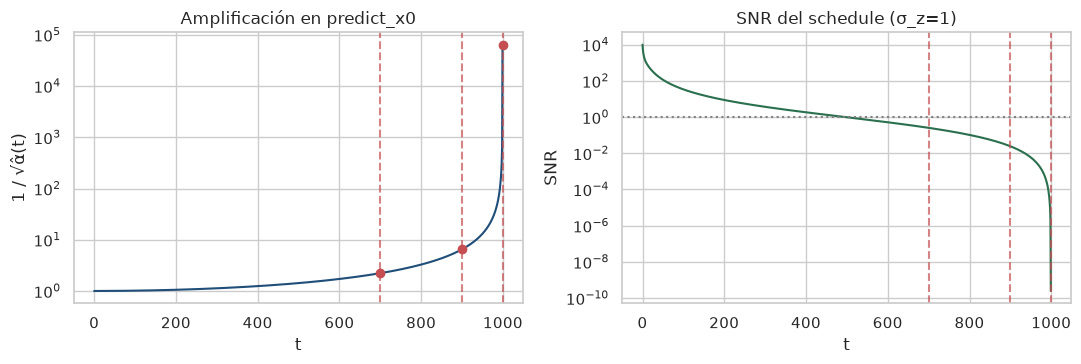

A t=999: 1/√α̂ ≈ 64171× — un error ε de 0.01 se amplifica a ~642 en pred_x0.


In [5]:
alpha_hat = diffusion.alpha_hat.detach().cpu().numpy()
t_axis = np.arange(len(alpha_hat))
inv_sqrt = 1.0 / np.sqrt(np.maximum(alpha_hat, 1e-30))
snr = snr_curve(alpha_hat, sigma_z=1.0)

highlight_t = [700, 900, 999]
rows = []
for t in highlight_t:
    rows.append({
        "t": t,
        "alpha_hat": float(alpha_hat[t]),
        "1/sqrt(alpha_hat)": float(inv_sqrt[t]),
        "amplif_(sqrt((1-a)/a))": amplification_factor(alpha_hat, t),
        "SNR": float(snr[t]),
    })
sched_df = pd.DataFrame(rows)
display(sched_df)
sched_df.to_csv(EXPORT_DIR / "schedule_highlights.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].semilogy(t_axis, inv_sqrt, color="#1f4e79", lw=1.5)
for t in highlight_t:
    axes[0].axvline(t, color="C3", ls="--", alpha=0.7)
    axes[0].scatter([t], [inv_sqrt[t]], color="C3", zorder=3)
axes[0].set_xlabel("t")
axes[0].set_ylabel("1 / √α̂(t)")
axes[0].set_title("Amplificación en predict_x0")

axes[1].semilogy(t_axis, snr, color="#2a6f4e", lw=1.5)
axes[1].axhline(1.0, color="gray", ls=":")
for t in highlight_t:
    axes[1].axvline(t, color="C3", ls="--", alpha=0.7)
axes[1].set_xlabel("t")
axes[1].set_ylabel("SNR")
axes[1].set_title("SNR del schedule (σ_z=1)")
plt.tight_layout()
fig.savefig(EXPORT_DIR / "01_schedule_amplification.png", dpi=140, bbox_inches="tight")
plt.show()

print(
    f"A t=999: 1/√α̂ ≈ {inv_sqrt[999]:.0f}× — un error ε de 0.01 se amplifica a ~{0.01 * inv_sqrt[999]:.0f} en pred_x0."
)

## 2. One-step: ¿falla el UNet en t alto?

Sin loop DDIM: ruido el latente GT a un `t` fijo, predice ε, reconstruye `pred_x0`.  
Separa **error de predicción** de **retroalimentación del sampler**.


one-step: 100%|██████████| 36/36 [00:48<00:00,  1.36s/it]


,t,eps_mse_mean,latent_mse_mean,latent_corr_mean,pred_x0_std_mean,pred_x0_abs_max_mean,pred_x0_abs_max_max
0,50,0.029779,2.600412e-04,0.999863,0.982605,5.601252,7.122832
1,100,0.020349,6.033910e-04,0.999683,0.983302,5.573445,7.044234
2,300,0.010235,2.797777e-03,0.998539,0.980706,5.577613,7.108846
3,500,0.006796,7.014042e-03,0.996354,0.986975,5.449521,6.940896
4,700,0.004808,1.901852e-02,0.990498,1.003861,5.733344,7.314897
5,900,0.003525,1.457752e-01,0.958413,1.184255,7.250953,8.934587
6,999,0.009045,3.724868e+07,0.782008,5914.673730,34680.427734,35304.484375


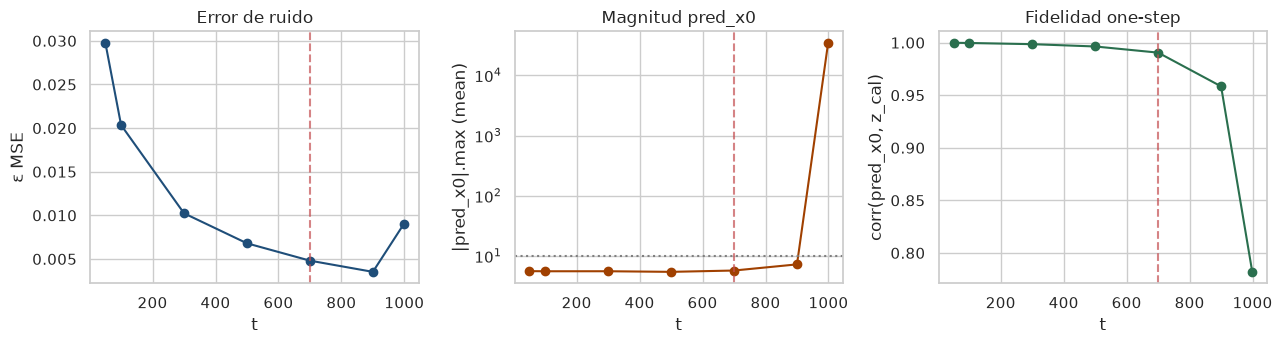

Resumen t≥700:
  t  eps_mse_mean  latent_mse_mean  latent_corr_mean  pred_x0_std_mean  pred_x0_abs_max_mean  pred_x0_abs_max_max
700      0.004808     1.901852e-02          0.990498          1.003861              5.733344             7.314897
900      0.003525     1.457752e-01          0.958413          1.184255              7.250953             8.934587
999      0.009045     3.724868e+07          0.782008       5914.673730          34680.427734         35304.484375


In [6]:
one_step_rows = []
subject_cache = []  # reutilizado en secciones 3–4

for MRI, Abeta, name, label in tqdm(loader, desc="one-step"):
    sid = subject_id_from_name(name)
    if sid not in SELECTED_IDS:
        continue
    MRI_t = torch.as_tensor(np.expand_dims(MRI, 1), dtype=torch.float32, device=device)
    spect = torch.as_tensor(np.expand_dims(Abeta, 1), dtype=torch.float32, device=device)
    label_b = label.to(device).reshape(-1).long()

    with torch.no_grad():
        z_gt = aae.encoder(spect)
        z_cal = diffusion.normalize_latent(z_gt)
        cond, precomputed = mri_condition(mri_encoder, MRI_t)

    subject_cache.append({
        "ID": sid,
        "label": int(label_b.item()),
        "z_gt": z_gt.detach(),
        "z_cal": z_cal.detach(),
        "spect": spect.detach(),
        "cond": cond.detach(),
        "precomputed": precomputed,
        "label_b": label_b.detach(),
    })

    seed_torch(SEED)
    for t_val in ONE_STEP_T:
        z_hat, eps_true, eps_pred = one_step_denoise(
            diffusion, unet, z_cal, t_val, cond, label_b, precomputed, USE_LABEL
        )
        eps_mse = float(((eps_pred - eps_true) ** 2).mean())
        m = latent_metrics(z_hat, z_cal)
        st = _tensor_stats(z_hat)
        one_step_rows.append({
            "ID": sid,
            "t": t_val,
            "eps_mse": eps_mse,
            "latent_mse": m["latent_mse"],
            "latent_corr": m["latent_corr"],
            "pred_x0_std": st["std"],
            "pred_x0_abs_max": st["abs_max"],
            "inv_sqrt_alpha": float(1.0 / max(np.sqrt(float(alpha_hat[t_val])), 1e-30)),
        })

one_df = pd.DataFrame(one_step_rows)
one_summary = (
    one_df.groupby("t", as_index=False)
    .agg(
        eps_mse_mean=("eps_mse", "mean"),
        latent_mse_mean=("latent_mse", "mean"),
        latent_corr_mean=("latent_corr", "mean"),
        pred_x0_std_mean=("pred_x0_std", "mean"),
        pred_x0_abs_max_mean=("pred_x0_abs_max", "mean"),
        pred_x0_abs_max_max=("pred_x0_abs_max", "max"),
    )
)
display(one_summary)
one_df.to_csv(EXPORT_DIR / "02_one_step_per_subject.csv", index=False)
one_summary.to_csv(EXPORT_DIR / "02_one_step_summary.csv", index=False)

fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
axes[0].plot(one_summary["t"], one_summary["eps_mse_mean"], "o-", color="#1f4e79")
axes[0].axvline(700, color="C3", ls="--", alpha=0.7)
axes[0].set_xlabel("t"); axes[0].set_ylabel("ε MSE"); axes[0].set_title("Error de ruido")

axes[1].semilogy(one_summary["t"], one_summary["pred_x0_abs_max_mean"], "o-", color="#a04000")
axes[1].axhline(EXPLODE_MAX_ABS, color="gray", ls=":")
axes[1].axvline(700, color="C3", ls="--", alpha=0.7)
axes[1].set_xlabel("t"); axes[1].set_ylabel("|pred_x0|.max (mean)"); axes[1].set_title("Magnitud pred_x0")

axes[2].plot(one_summary["t"], one_summary["latent_corr_mean"], "o-", color="#2a6f4e")
axes[2].axvline(700, color="C3", ls="--", alpha=0.7)
axes[2].set_xlabel("t"); axes[2].set_ylabel("corr(pred_x0, z_cal)"); axes[2].set_title("Fidelidad one-step")
plt.tight_layout()
fig.savefig(EXPORT_DIR / "02_one_step_vs_t.png", dpi=140, bbox_inches="tight")
plt.show()

high = one_summary[one_summary["t"] >= 700]
print("Resumen t≥700:")
print(high.to_string(index=False))

## 3. DDIM instrumentado — ¿en qué paso explota `pred_x0`?

Muestreo desde ruido puro (como en inferencia real), **sin clamp**, registrando stats por paso.


DDIM no-clamp: 100%|██████████| 10/10 [07:08<00:00, 42.86s/it]


,ID,exploded,first_step_idx,first_t,first_abs_max,final_raw_std,PSNR,SSIM
0,3107,True,0,999,29903.064453,31670.820312,10.832,0.275
1,3108,True,0,999,29866.267578,32268.183594,18.395,0.428
2,3116,True,0,999,29802.056641,31737.902344,15.720,0.361
3,3119,True,0,999,29964.691406,31626.103516,18.358,0.448
4,3120,True,0,999,29842.111328,32096.964844,16.857,0.412
5,3165,True,0,999,30935.744141,31714.246094,20.888,0.538
6,3172,True,0,999,30939.201172,31236.132812,20.081,0.501
7,3188,True,0,999,30912.425781,31454.230469,19.309,0.447
8,3191,True,0,999,31090.025391,31977.912109,19.994,0.459
9,3320,True,0,999,30929.914062,31549.730469,22.135,0.547


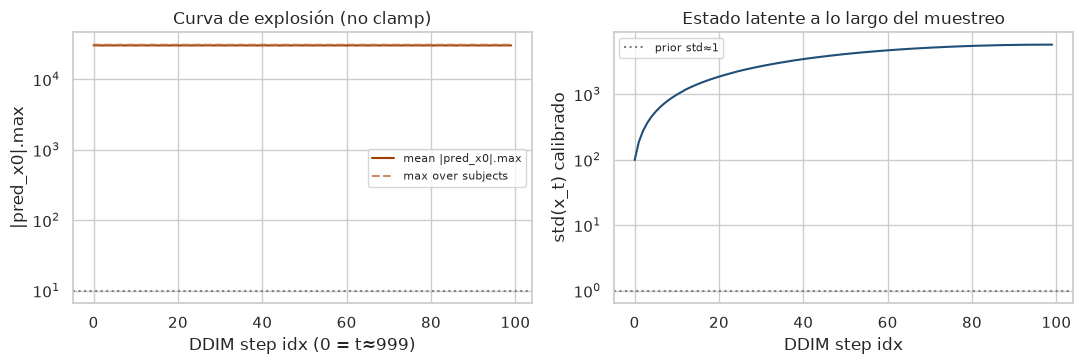

Explosión detectada en 10/10 sujetos.
Primer paso medio: idx=0.0, t=999, |pred_x0|.max≈30419
Latente final raw: std mean=31733.2 (GT esperado ~5.5)


In [7]:
traj_all = []
explode_rows = []

for subj in tqdm(subject_cache, desc="DDIM no-clamp"):
    z_raw, traj = ddim_instrumented(
        diffusion=diffusion,
        unet=unet,
        cond=subj["cond"],
        label=subj["label_b"],
        precomputed=subj["precomputed"],
        use_label=USE_LABEL,
        sampling_steps=DDIM_STEPS,
        clamp_abs=None,
        seed=SEED,
    )
    traj = traj.copy()
    traj["ID"] = subj["ID"]
    traj["mode"] = "no_clamp"
    traj_all.append(traj)

    info = first_explosion_step(traj)
    final_cal = diffusion.normalize_latent(z_raw)
    explode_rows.append({
        "ID": subj["ID"],
        "mode": "no_clamp",
        **info,
        "final_raw_std": float(z_raw.std()),
        "final_raw_abs_max": float(z_raw.abs().max()),
        "final_cal_std": float(final_cal.std()),
        "latent_mse_vs_gt": latent_metrics(z_raw, subj["z_gt"])["latent_mse"],
        "latent_corr_vs_gt": latent_metrics(z_raw, subj["z_gt"])["latent_corr"],
        **image_metrics(aae, subj["spect"], z_raw),
    })

traj_noclamp = pd.concat(traj_all, ignore_index=True)
explode_df = pd.DataFrame(explode_rows)
display(explode_df[["ID", "exploded", "first_step_idx", "first_t", "first_abs_max", "final_raw_std", "PSNR", "SSIM"]])

traj_noclamp.to_csv(EXPORT_DIR / "03_traj_no_clamp.csv", index=False)
explode_df.to_csv(EXPORT_DIR / "03_explosion_summary_no_clamp.csv", index=False)

agg = (
    traj_noclamp.groupby("step_idx", as_index=False)
    .agg(
        t=("t", "first"),
        pred_x0_abs_max_mean=("pred_x0_abs_max", "mean"),
        pred_x0_abs_max_max=("pred_x0_abs_max", "max"),
        pred_x0_std_mean=("pred_x0_std", "mean"),
        x_std_mean=("x_std", "mean"),
        inv_sqrt_alpha=("inv_sqrt_alpha", "first"),
    )
)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].semilogy(agg["step_idx"], agg["pred_x0_abs_max_mean"], "-", color="#a04000", label="mean |pred_x0|.max")
axes[0].semilogy(agg["step_idx"], agg["pred_x0_abs_max_max"], "--", color="#c07040", alpha=0.8, label="max over subjects")
axes[0].axhline(EXPLODE_MAX_ABS, color="gray", ls=":")
axes[0].set_xlabel("DDIM step idx (0 = t≈999)")
axes[0].set_ylabel("|pred_x0|.max")
axes[0].set_title("Curva de explosión (no clamp)")
axes[0].legend(fontsize=8)

axes[1].semilogy(agg["step_idx"], agg["x_std_mean"], "-", color="#1f4e79")
axes[1].axhline(1.0, color="gray", ls=":", label="prior std≈1")
axes[1].set_xlabel("DDIM step idx")
axes[1].set_ylabel("std(x_t) calibrado")
axes[1].set_title("Estado latente a lo largo del muestreo")
axes[1].legend(fontsize=8)
plt.tight_layout()
fig.savefig(EXPORT_DIR / "03_explosion_curve_no_clamp.png", dpi=140, bbox_inches="tight")
plt.show()

n_exp = int(explode_df["exploded"].sum())
print(f"Explosión detectada en {n_exp}/{len(explode_df)} sujetos.")
if n_exp:
    print(
        "Primer paso medio: idx={:.1f}, t={:.0f}, |pred_x0|.max≈{:.0f}".format(
            explode_df.loc[explode_df.exploded, "first_step_idx"].mean(),
            explode_df.loc[explode_df.exploded, "first_t"].mean(),
            explode_df.loc[explode_df.exploded, "first_abs_max"].mean(),
        )
    )
print(
    f"Latente final raw: std mean={explode_df['final_raw_std'].mean():.1f} "
    f"(GT esperado ~{LATENT_STD:.1f})"
)

## 4. A/B — no clamp vs clamp estático

Misma semilla y mismos sujetos. Clamp en **espacio calibrado**:

```python
pred_x0 = pred_x0.clamp(-s, s)   # s ∈ {3, 5}
```

Esto es *static thresholding* (patrón habitual en DDPM/SD). No cambia el entrenamiento; solo el sampler.


DDIM clamp±5.0: 100%|██████████| 10/10 [07:09<00:00, 42.94s/it]


,mode,n,exploded_frac,final_raw_std_mean,final_cal_std_mean,latent_mse_mean,latent_corr_mean,PSNR_mean,SSIM_mean
0,no_clamp,10,1.0,31733.222656,5722.861865,1.095832e+09,0.794357,18.2569,0.4416
1,clamp_3,10,0.0,5.103802,0.920434,1.836152e+01,0.714448,15.8911,0.5522
2,clamp_5,10,0.0,10.780202,1.944133,6.710691e+01,0.741634,15.6520,0.5146


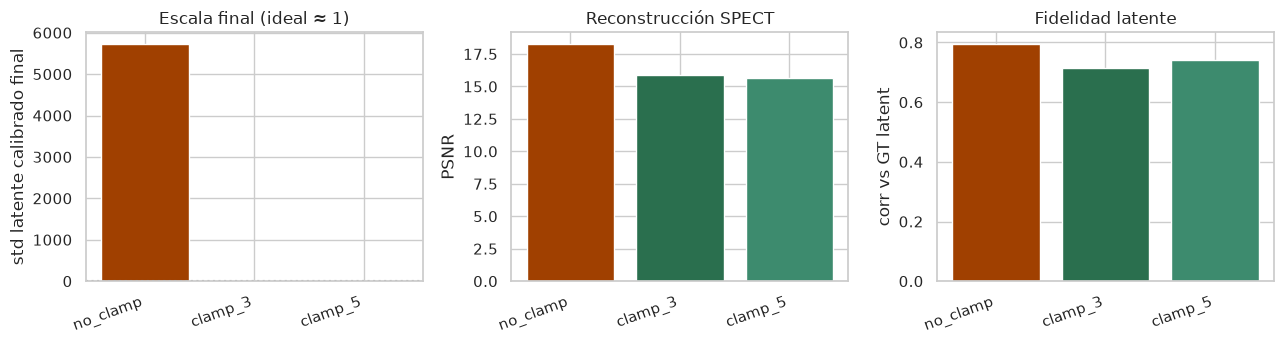

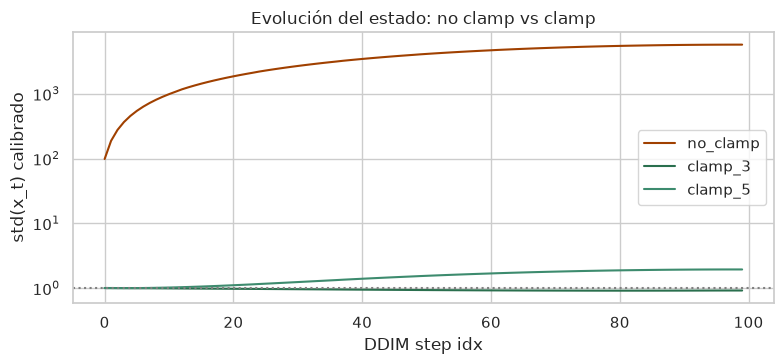

In [8]:
ab_rows = list(explode_df.to_dict("records"))  # ya incluye no_clamp
traj_clamp_parts = []

for s in CLAMP_BOUNDS:
    for subj in tqdm(subject_cache, desc=f"DDIM clamp±{s}"):
        z_raw, traj = ddim_instrumented(
            diffusion=diffusion,
            unet=unet,
            cond=subj["cond"],
            label=subj["label_b"],
            precomputed=subj["precomputed"],
            use_label=USE_LABEL,
            sampling_steps=DDIM_STEPS,
            clamp_abs=s,
            seed=SEED,
        )
        traj = traj.copy()
        traj["ID"] = subj["ID"]
        traj["mode"] = f"clamp_{s:g}"
        traj_clamp_parts.append(traj)

        info = first_explosion_step(traj)  # usa pred_x0 PRE-clamp (instrumentación)
        # Explosión "efectiva" post-clamp: mirar x_std final
        final_cal = diffusion.normalize_latent(z_raw)
        ab_rows.append({
            "ID": subj["ID"],
            "mode": f"clamp_{s:g}",
            **info,
            "final_raw_std": float(z_raw.std()),
            "final_raw_abs_max": float(z_raw.abs().max()),
            "final_cal_std": float(final_cal.std()),
            "latent_mse_vs_gt": latent_metrics(z_raw, subj["z_gt"])["latent_mse"],
            "latent_corr_vs_gt": latent_metrics(z_raw, subj["z_gt"])["latent_corr"],
            **image_metrics(aae, subj["spect"], z_raw),
        })

ab_df = pd.DataFrame(ab_rows)
traj_all_modes = pd.concat([traj_noclamp] + traj_clamp_parts, ignore_index=True)

ab_summary = (
    ab_df.groupby("mode", as_index=False)
    .agg(
        n=("ID", "count"),
        exploded_frac=("exploded", "mean"),
        final_raw_std_mean=("final_raw_std", "mean"),
        final_cal_std_mean=("final_cal_std", "mean"),
        latent_mse_mean=("latent_mse_vs_gt", "mean"),
        latent_corr_mean=("latent_corr_vs_gt", "mean"),
        PSNR_mean=("PSNR", "mean"),
        SSIM_mean=("SSIM", "mean"),
    )
)
# Orden legible
order = ["no_clamp"] + [f"clamp_{s:g}" for s in CLAMP_BOUNDS]
ab_summary["mode"] = pd.Categorical(ab_summary["mode"], categories=order, ordered=True)
ab_summary = ab_summary.sort_values("mode").reset_index(drop=True)
display(ab_summary)

ab_df.to_csv(EXPORT_DIR / "04_ab_per_subject.csv", index=False)
ab_summary.to_csv(EXPORT_DIR / "04_ab_summary.csv", index=False)
traj_all_modes.to_csv(EXPORT_DIR / "04_traj_all_modes.csv", index=False)

fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
x = np.arange(len(ab_summary))
labels = [str(m) for m in ab_summary["mode"]]

axes[0].bar(x, ab_summary["final_cal_std_mean"], color=["#a04000", "#2a6f4e", "#3d8b6e"][: len(x)])
axes[0].axhline(1.0, color="gray", ls=":")
axes[0].set_xticks(x); axes[0].set_xticklabels(labels, rotation=20, ha="right")
axes[0].set_ylabel("std latente calibrado final")
axes[0].set_title("Escala final (ideal ≈ 1)")

axes[1].bar(x, ab_summary["PSNR_mean"], color=["#a04000", "#2a6f4e", "#3d8b6e"][: len(x)])
axes[1].set_xticks(x); axes[1].set_xticklabels(labels, rotation=20, ha="right")
axes[1].set_ylabel("PSNR")
axes[1].set_title("Reconstrucción SPECT")

axes[2].bar(x, ab_summary["latent_corr_mean"], color=["#a04000", "#2a6f4e", "#3d8b6e"][: len(x)])
axes[2].set_xticks(x); axes[2].set_xticklabels(labels, rotation=20, ha="right")
axes[2].set_ylabel("corr vs GT latent")
axes[2].set_title("Fidelidad latente")
plt.tight_layout()
fig.savefig(EXPORT_DIR / "04_ab_bars.png", dpi=140, bbox_inches="tight")
plt.show()

# Curvas pred_x0 por modo (media sobre sujetos)
fig, ax = plt.subplots(figsize=(8, 3.8))
for mode, color in zip(order, ["#a04000", "#2a6f4e", "#3d8b6e"]):
    part = traj_all_modes[traj_all_modes["mode"] == mode]
    if part.empty:
        continue
    g = part.groupby("step_idx")["x_std"].mean()
    ax.semilogy(g.index, g.values, "-", color=color, label=mode)
ax.axhline(1.0, color="gray", ls=":")
ax.set_xlabel("DDIM step idx")
ax.set_ylabel("std(x_t) calibrado")
ax.set_title("Evolución del estado: no clamp vs clamp")
ax.legend()
plt.tight_layout()
fig.savefig(EXPORT_DIR / "04_x_std_trajectories.png", dpi=140, bbox_inches="tight")
plt.show()

## 5. Causas y posibles soluciones

Interpretación automática a partir de las tablas de arriba + checklist accionable.


In [9]:
noclamp = ab_summary[ab_summary["mode"].astype(str) == "no_clamp"].iloc[0]
best_clamp = ab_summary[ab_summary["mode"].astype(str).str.startswith("clamp_")].sort_values(
    "PSNR_mean", ascending=False
).iloc[0]

print("=== Diagnóstico ===")
print(f"1/√α̂(t=999) ≈ {inv_sqrt[999]:.0f}×")
print(
    f"One-step t=999: pred_x0 |max| medio = "
    f"{one_summary.loc[one_summary.t == 999, 'pred_x0_abs_max_mean'].iloc[0]:.1f}"
)
print(
    f"DDIM no-clamp: std calibrado final medio = {noclamp['final_cal_std_mean']:.1f} "
    f"(ideal ~1); PSNR={noclamp['PSNR_mean']:.2f}"
)
print(
    f"Mejor clamp ({best_clamp['mode']}): std cal={best_clamp['final_cal_std_mean']:.2f}, "
    f"PSNR={best_clamp['PSNR_mean']:.2f} (Δ PSNR = {best_clamp['PSNR_mean'] - noclamp['PSNR_mean']:+.2f})"
)

causes = pd.DataFrame([
    {
        "causa": "Sin bound en pred_x0",
        "evidencia": "Explosión en primeros pasos DDIM; latente final ~10^3–10^4 σ",
        "mitigacion": "Static/dynamic thresholding en Diffusion.sample()",
        "tipo": "inferencia",
    },
    {
        "causa": "UNet débil en t alto (t>700)",
        "evidencia": "One-step: eps_mse / |pred_x0| colapsan en 900–999",
        "mitigacion": "HIGH_T_SAMPLE_PROB=0.5 (h05_calib_roi3ch) o biased sampling",
        "tipo": "entrenamiento",
    },
    {
        "causa": "α̂≈0 en cosine t=999",
        "evidencia": f"1/√α̂ ≈ {inv_sqrt[999]:.0f}",
        "mitigacion": "Empezar DDIM desde t más bajo / recortar schedule",
        "tipo": "schedule/sampler",
    },
    {
        "causa": "Retroalimentación multi-paso",
        "evidencia": "std(x_t) crece monótonamente tras el primer paso malo",
        "mitigacion": "Clamp + mejor ε en alto-t (ambos)",
        "tipo": "combinada",
    },
])
display(causes)
causes.to_csv(EXPORT_DIR / "05_causes_mitigations.csv", index=False)

print("\n=== Recomendación práctica ===")
print("1. Corto plazo (inferencia): añadir pred_x0.clamp(-s, s) en main.py Diffusion.sample().")
print("2. Medio plazo (entrenamiento): re-correr / evaluar h05_calib_roi3ch (high-t 0.5).")
print("3. Ideal: ambos — UNet más fiable en alto-t + sampler con bound.")
print(f"\nArtefactos en: {EXPORT_DIR}")

=== Diagnóstico ===
1/√α̂(t=999) ≈ 64171×
One-step t=999: pred_x0 |max| medio = 34680.4
DDIM no-clamp: std calibrado final medio = 5722.9 (ideal ~1); PSNR=18.26
Mejor clamp (clamp_3): std cal=0.92, PSNR=15.89 (Δ PSNR = -2.37)


,causa,evidencia,mitigacion,tipo
0,Sin bound en pred_x0,Explosión en primeros pasos DDIM; latente fina...,Static/dynamic thresholding en Diffusion.sample(),inferencia
1,UNet débil en t alto (t>700),One-step: eps_mse / |pred_x0| colapsan en 900–999,HIGH_T_SAMPLE_PROB=0.5 (h05_calib_roi3ch) o bi...,entrenamiento
2,α̂≈0 en cosine t=999,1/√α̂ ≈ 64171,Empezar DDIM desde t más bajo / recortar schedule,schedule/sampler
3,Retroalimentación multi-paso,std(x_t) crece monótonamente tras el primer pa...,Clamp + mejor ε en alto-t (ambos),combinada



=== Recomendación práctica ===
1. Corto plazo (inferencia): añadir pred_x0.clamp(-s, s) en main.py Diffusion.sample().
2. Medio plazo (entrenamiento): re-correr / evaluar h05_calib_roi3ch (high-t 0.5).
3. Ideal: ambos — UNet más fiable en alto-t + sampler con bound.

Artefactos en: /workspace/IL-CLDM/result/clampNoClamp
